In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

print("Libraries imported successfully")

Libraries imported successfully


In [26]:
# Load dataset
df = pd.read_csv("wdbc.csv")

# Display first five records
display(df.head())

# Dataset dimensions
print("Dataset shape:", df.shape)

# Column information
df.info()

# Statistical summary
display(df.describe())

,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Dataset shape: (569, 32)
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   mean_radius              569 non-null    float64
 3   mean_texture             569 non-null    float64
 4   mean_perimeter           569 non-null    float64
 5   mean_area                569 non-null    float64
 6   mean_smoothness          569 non-null    float64
 7   mean_compactness         569 non-null    float64
 8   mean_concavity           569 non-null    float64
 9   mean_concave_points      569 non-null    float64
 10  mean_symmetry            569 non-null    float64
 11  mean_fractal_dimension   569 non-null    float64
 12  se_radius                569 non-null    float64
 13  se_texture               569 non-null    float64
 14  se_perimeter

,id,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [27]:
# Check missing values
print("Missing values:")
print(df.isnull().sum().sum())

# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

# Check target distribution
print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())

# Target distribution in percentage
print("\nDiagnosis percentage:")
print(df["diagnosis"].value_counts(normalize=True) * 100)

Missing values:
0
Duplicate records: 0

Diagnosis distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Diagnosis percentage:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


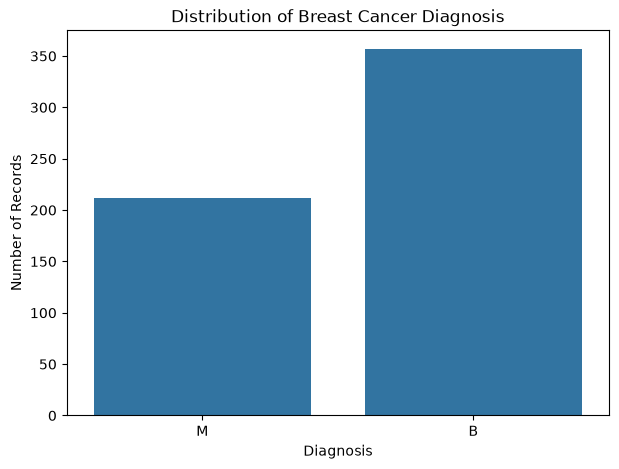

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="diagnosis")

plt.title("Distribution of Breast Cancer Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")

plt.show()

In [29]:
# Remove ID column
df = df.drop(columns=["id"])

# Separate input features and target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget mapping:")
print("Benign = 0")
print("Malignant = 1")

Input features shape: (569, 30)
Target shape: (569,)

Target mapping:
Benign = 0
Malignant = 1


In [30]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (455, 30)
Testing data shape: (114, 30)

Training target distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing target distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [31]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Fit scaler only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to testing data
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("Original testing shape:", X_test.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Original training shape: (455, 30)
Scaled training shape: (455, 30)
Original testing shape: (114, 30)
Scaled testing shape: (114, 30)


In [32]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Predict test data
y_pred_lr = logistic_model.predict(X_test_scaled)

# Predict probabilities for AUC calculation
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression training completed!")
print("Number of predictions:", len(y_pred_lr))

Logistic Regression training completed!
Number of predictions: 114


In [33]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_auc = roc_auc_score(y_test, y_prob_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_mcc = matthews_corrcoef(y_test, y_pred_lr)

# Display results
print("Logistic Regression - Evaluation Results")
print("----------------------------------------")
print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"AUC Score : {lr_auc:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1 Score  : {lr_f1:.4f}")
print(f"MCC Score : {lr_mcc:.4f}")

Logistic Regression - Evaluation Results
----------------------------------------
Accuracy  : 0.9649
AUC Score : 0.9960
Precision : 0.9750
Recall    : 0.9286
F1 Score  : 0.9512
MCC Score : 0.9245


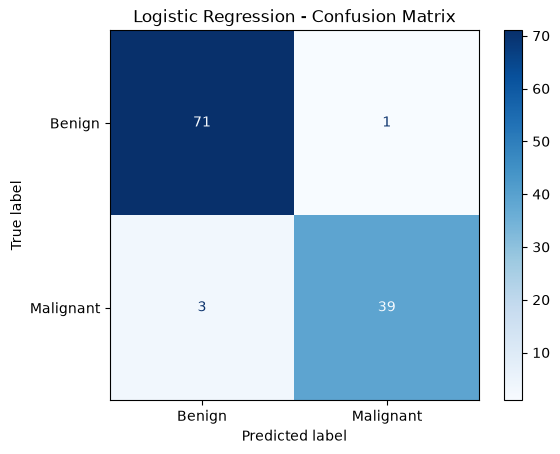

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [35]:
from sklearn.tree import DecisionTreeClassifier

# Initialize Decision Tree
decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# Train using original training data
decision_tree_model.fit(X_train, y_train)

# Predict test data
y_pred_dt = decision_tree_model.predict(X_test)

# Predict probabilities for AUC
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree training completed!")
print("Number of predictions:", len(y_pred_dt))

Decision Tree training completed!
Number of predictions: 114


In [36]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_auc = roc_auc_score(y_test, y_prob_dt)
dt_precision = precision_score(y_test, y_pred_dt)
dt_recall = recall_score(y_test, y_pred_dt)
dt_f1 = f1_score(y_test, y_pred_dt)
dt_mcc = matthews_corrcoef(y_test, y_pred_dt)

print("Decision Tree - Evaluation Results")
print("-----------------------------------")
print(f"Accuracy  : {dt_accuracy:.4f}")
print(f"AUC Score : {dt_auc:.4f}")
print(f"Precision : {dt_precision:.4f}")
print(f"Recall    : {dt_recall:.4f}")
print(f"F1 Score  : {dt_f1:.4f}")
print(f"MCC Score : {dt_mcc:.4f}")

Decision Tree - Evaluation Results
-----------------------------------
Accuracy  : 0.9298
AUC Score : 0.9246
Precision : 0.9048
Recall    : 0.9048
F1 Score  : 0.9048
MCC Score : 0.8492


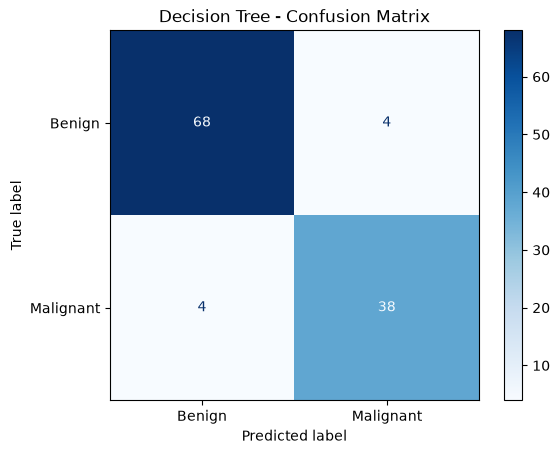

In [37]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [38]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize KNN classifier
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="minkowski",
    p=2
)

# Train model
knn_model.fit(X_train_scaled, y_train)

# Predict test data
y_pred_knn = knn_model.predict(X_test_scaled)

# Predict probabilities for AUC
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

print("KNN training completed!")
print("Number of predictions:", len(y_pred_knn))

KNN training completed!
Number of predictions: 114


In [39]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_auc = roc_auc_score(y_test, y_prob_knn)
knn_precision = precision_score(y_test, y_pred_knn)
knn_recall = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)
knn_mcc = matthews_corrcoef(y_test, y_pred_knn)

print("KNN - Evaluation Results")
print("-------------------------")
print(f"Accuracy  : {knn_accuracy:.4f}")
print(f"AUC Score : {knn_auc:.4f}")
print(f"Precision : {knn_precision:.4f}")
print(f"Recall    : {knn_recall:.4f}")
print(f"F1 Score  : {knn_f1:.4f}")
print(f"MCC Score : {knn_mcc:.4f}")

KNN - Evaluation Results
-------------------------
Accuracy  : 0.9561
AUC Score : 0.9823
Precision : 0.9744
Recall    : 0.9048
F1 Score  : 0.9383
MCC Score : 0.9058


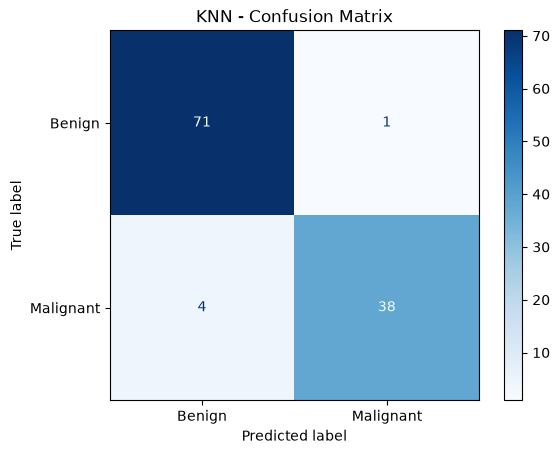

In [40]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues")
plt.title("KNN - Confusion Matrix")
plt.show()

In [41]:
from sklearn.naive_bayes import GaussianNB

# Initialize Gaussian Naive Bayes
naive_bayes_model = GaussianNB()

# Train the model
naive_bayes_model.fit(X_train_scaled, y_train)

# Predict test data
y_pred_nb = naive_bayes_model.predict(X_test_scaled)

# Predict probabilities for AUC
y_prob_nb = naive_bayes_model.predict_proba(X_test_scaled)[:, 1]

print("Gaussian Naive Bayes training completed!")
print("Number of predictions:", len(y_pred_nb))

Gaussian Naive Bayes training completed!
Number of predictions: 114


In [42]:
nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_auc = roc_auc_score(y_test, y_prob_nb)
nb_precision = precision_score(y_test, y_pred_nb)
nb_recall = recall_score(y_test, y_pred_nb)
nb_f1 = f1_score(y_test, y_pred_nb)
nb_mcc = matthews_corrcoef(y_test, y_pred_nb)

print("Gaussian Naive Bayes - Evaluation Results")
print("------------------------------------------")
print(f"Accuracy  : {nb_accuracy:.4f}")
print(f"AUC Score : {nb_auc:.4f}")
print(f"Precision : {nb_precision:.4f}")
print(f"Recall    : {nb_recall:.4f}")
print(f"F1 Score  : {nb_f1:.4f}")
print(f"MCC Score : {nb_mcc:.4f}")

Gaussian Naive Bayes - Evaluation Results
------------------------------------------
Accuracy  : 0.9211
AUC Score : 0.9891
Precision : 0.9231
Recall    : 0.8571
F1 Score  : 0.8889
MCC Score : 0.8292


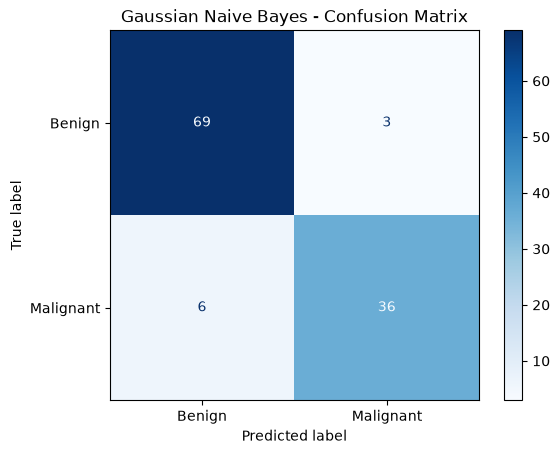

In [43]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues")
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.show()

In [44]:
from sklearn.svm import SVC

# Initialize Support Vector Machine
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Predict test data
y_pred_svm = svm_model.predict(X_test_scaled)

# Predict probabilities for AUC calculation
y_score_svm = svm_model.decision_function(X_test_scaled)

print("SVM training completed!")
print("Number of predictions:", len(y_pred_svm))

SVM training completed!
Number of predictions: 114


In [45]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_auc = roc_auc_score(y_test, y_score_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)
svm_mcc = matthews_corrcoef(y_test, y_pred_svm)

print("Support Vector Machine - Evaluation Results")
print("--------------------------------------------")
print(f"Accuracy  : {svm_accuracy:.4f}")
print(f"AUC Score : {svm_auc:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1 Score  : {svm_f1:.4f}")
print(f"MCC Score : {svm_mcc:.4f}")

Support Vector Machine - Evaluation Results
--------------------------------------------
Accuracy  : 0.9737
AUC Score : 0.9947
Precision : 1.0000
Recall    : 0.9286
F1 Score  : 0.9630
MCC Score : 0.9442


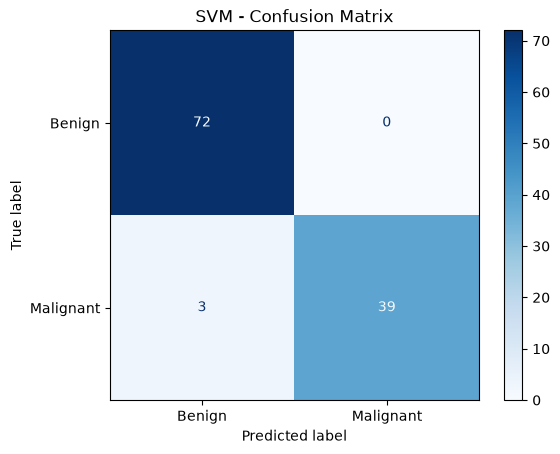

In [46]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues")
plt.title("SVM - Confusion Matrix")
plt.show()

In [47]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Gaussian Naive Bayes",
        "SVM"
    ],
    "Accuracy": [
        lr_accuracy, dt_accuracy, knn_accuracy, nb_accuracy, svm_accuracy
    ],
    "AUC Score": [
        lr_auc, dt_auc, knn_auc, nb_auc, svm_auc
    ],
    "Precision": [
        lr_precision, dt_precision, knn_precision, nb_precision, svm_precision
    ],
    "Recall": [
        lr_recall, dt_recall, knn_recall, nb_recall, svm_recall
    ],
    "F1 Score": [
        lr_f1, dt_f1, knn_f1, nb_f1, svm_f1
    ],
    "MCC": [
        lr_mcc, dt_mcc, knn_mcc, nb_mcc, svm_mcc
    ]
})

display(results.round(4))

,Model,Accuracy,AUC Score,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Gaussian Naive Bayes,0.9211,0.9891,0.9231,0.8571,0.8889,0.8292
4,SVM,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


In [48]:
import os
import joblib

# Create folder to store trained models
os.makedirs("saved_models", exist_ok=True)

# Save all five trained models
joblib.dump(logistic_model, "saved_models/logistic_regression.pkl")
joblib.dump(decision_tree_model, "saved_models/decision_tree.pkl")
joblib.dump(knn_model, "saved_models/knn.pkl")
joblib.dump(naive_bayes_model, "saved_models/naive_bayes.pkl")
joblib.dump(svm_model, "saved_models/svm.pkl")

# Save the fitted scaler
joblib.dump(scaler, "saved_models/scaler.pkl")

# Save feature names and their expected order
joblib.dump(X.columns.tolist(), "saved_models/feature_names.pkl")

print("All five models and preprocessing artifacts saved successfully!")

All five models and preprocessing artifacts saved successfully!


In [49]:
import os
import joblib

saved_files = os.listdir("saved_models")

print("Files inside saved_models:")
for file in sorted(saved_files):
    print(file)

# Verify that all expected files exist
expected_files = [
    "logistic_regression.pkl",
    "decision_tree.pkl",
    "knn.pkl",
    "naive_bayes.pkl",
    "svm.pkl",
    "scaler.pkl",
    "feature_names.pkl"
]

for file in expected_files:
    assert os.path.exists(os.path.join("saved_models", file)), \
        f"Missing file: {file}"

print("\nAll model and preprocessing files verified!")

Files inside saved_models:
decision_tree.pkl
feature_names.pkl
knn.pkl
logistic_regression.pkl
naive_bayes.pkl
scaler.pkl
svm.pkl

All model and preprocessing files verified!


In [50]:
# Create a copy of the held-out test features
test_data = X_test.copy()

# Add the actual diagnosis labels
test_data["diagnosis"] = y_test.map({
    0: "B",
    1: "M"
})

# Save test data
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)

display(test_data.head())

Test dataset saved successfully!
Test dataset shape: (114, 31)


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,diagnosis
120,11.41,10.82,73.34,403.3,0.09373,0.06685,0.03512,0.02623,0.1667,0.06113,...,15.97,83.74,510.5,0.1548,0.2390,0.21020,0.08958,0.3016,0.08523,B
250,20.94,23.56,138.90,1364.0,0.10070,0.16060,0.27120,0.13100,0.2205,0.05898,...,27.00,165.30,2010.0,0.1211,0.3172,0.69910,0.21050,0.3126,0.07849,M
375,16.17,16.07,106.30,788.5,0.09880,0.14380,0.06651,0.05397,0.1990,0.06572,...,19.14,113.10,861.5,0.1235,0.2550,0.21140,0.12510,0.3153,0.08960,B
99,14.42,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,...,30.86,109.50,826.4,0.1431,0.3026,0.31940,0.15650,0.2718,0.09353,M
455,13.38,30.72,86.34,557.2,0.09245,0.07426,0.02819,0.03264,0.1375,0.06016,...,41.61,96.69,705.6,0.1172,0.1421,0.07003,0.07763,0.2196,0.07675,B
